# Supplementary Figure 2: Associated terms

Recreate weighted term prevalence for eight packages from the sampled 2021-2025 title and abstract corpus. The helper merges listed word variants, removes structured-abstract headings, and returns the eight highest log-odds terms present in at least 2% of a package's records.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `notebooks/data/sfigure2_terms.csv` | Eight ranked terms per package with package prevalence, baseline prevalence and log-odds score | `census.figures.domains.enriched_terms()` used by `python -m census.figures.sfig2_terms`, aggregate export from the original local corpus |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/SFigure2__terms.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import sfig2_terms as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

Each package's aliases join the shared microscopy context through `_registry.build_boolean_query()`. Terms are compared across analysis packages. The displayed packages follow the eight panels in the figure module.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'napari']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
4,qupath,QuPath,"""QuPath"" AND ((microscopy OR microscope) AND H..."


## Read panel inputs

Load the committed data for the calculations below. Panels a-h show eight terms for each of eight packages. Filled points give package prevalence, open points give prevalence in the other analysis-package samples. We display all 64 committed aggregate rows.

In [3]:
term_table = pd.read_csv(SCRIPTS_DIR / 'notebooks/data/sfigure2_terms.csv')
assert set(term_table.tool_id) == set(figure.TOOLS)
assert term_table.groupby('tool_id').size().eq(8).all()
display(term_table)


,tool_id,word,tool_pct,base_pct,z
0,imagej,western-blot,8.622377,1.386302,27.719158
1,imagej,inhibit,27.283073,14.433495,22.619435
2,imagej,apoptosis,9.012258,2.903266,20.267356
3,imagej,treatment,26.538754,16.601560,16.921238
4,imagej,ros,4.464178,1.136145,16.388220
...,...,...,...,...,...
59,arivis,three-dimensional,9.550562,2.406051,9.729015
60,arivis,embryo,8.239700,1.992944,9.295910
61,arivis,segmentation,5.243446,1.064291,8.312296
62,arivis,protocol,8.239700,2.458232,8.000980


## Reconstruct panel quantities

Panels a-h show eight terms for each of eight packages. Filled points give package prevalence, open points give prevalence in the other analysis-package samples. We display all 64 committed aggregate rows.

In [4]:
assert term_table[['tool_pct', 'base_pct']].ge(0).all().all()
assert term_table[['tool_pct', 'base_pct']].le(100).all().all()
for package, rows in term_table.groupby('tool_id', sort=False):
    assert rows.z.is_monotonic_decreasing, package
print('Eight ranked aggregate terms for each of eight packages; prevalence bounds hold.')


Eight ranked aggregate terms for each of eight packages; prevalence bounds hold.


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

After refetching, call `census.figures.domains.load_corpus()` and `enriched_terms(corpus, package)` for each package in `census.figures.sfig2_terms.TOOLS`. Insert the `tool_id` column and concatenate the rows in that order, then save `notebooks/data/sfigure2_terms.csv` with `index=False`. This local aggregation runs offline once the corpus exists. The default cells render every panel from the 64 aggregate rows.

## Render all panels

Build `SFigure2__terms` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote SFigure2__terms.png/.pdf/.svg
SFigure2__terms: 2092 x 1298 pixels


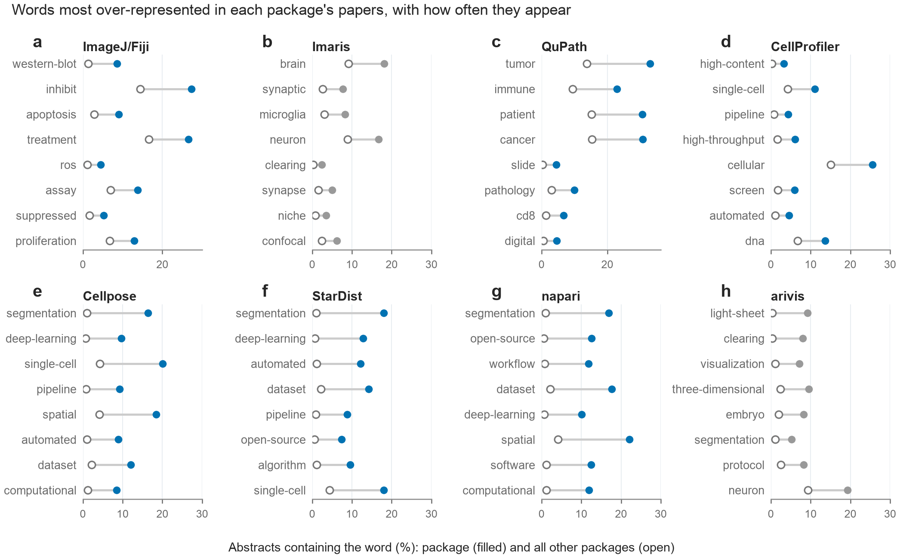

In [5]:
OUTPUT_STEM = 'SFigure2__terms'
fig = figure.build_figure(terms=term_table)
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


SFigure2__terms: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: b2ba82d918b1f4bcda7b1b48a812153a99ed9001916f401fb9dcd3c41e9e73ea
